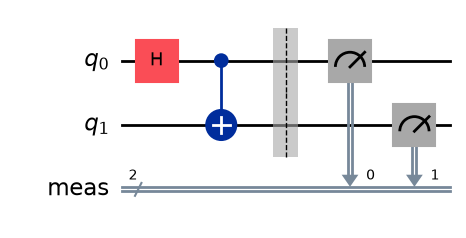

In [10]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.measure_all()
qc.draw("mpl")

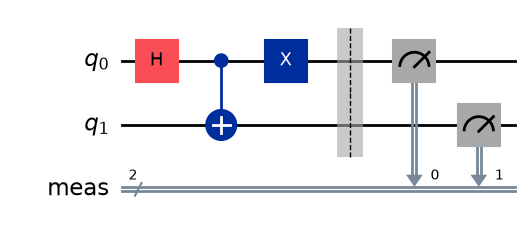

In [12]:
qc_modified = QuantumCircuit(2)
qc_modified.h(0)
qc_modified.cx(0,1)
qc_modified.x(0)
qc_modified.measure_all()
qc_modified.draw("mpl")

In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

In [14]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

backend = service.least_busy()
print(backend.name)

ibm_fez


In [25]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

qc_isa = pm.run(qc)
qc_isa_m = pm.run(qc_modified)

In [32]:
sampler = Sampler(mode=backend)
pubs = [qc_isa,qc_isa_m]
jobs = sampler.run(pubs,shots=100)
res = jobs.result()
counts_a = res[0].data.meas.get_counts()
counts_b = res[1].data.meas.get_counts()

C:\Users\laksh\AppData\Local\Temp\ipykernel_34220\2932395696.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


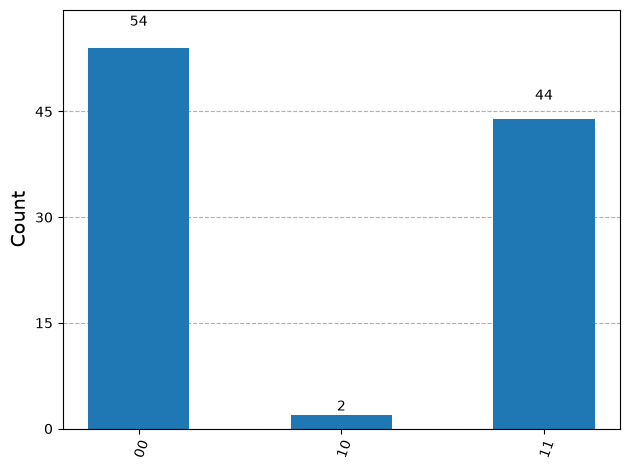

In [33]:
from qiskit.visualization import plot_histogram

plot_histogram(counts_a)

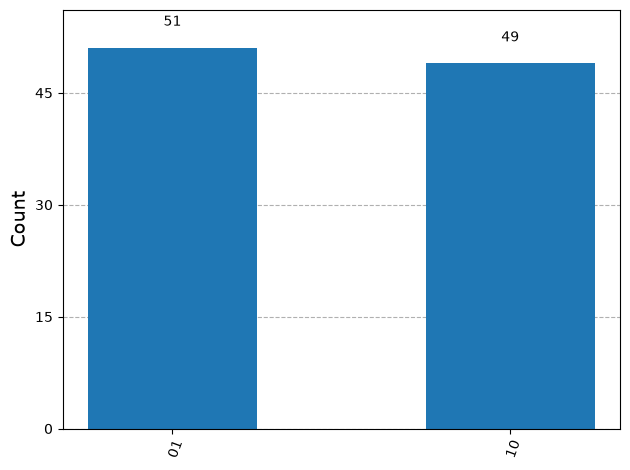

In [34]:
from qiskit.visualization import plot_histogram

plot_histogram(counts_b)

The original circuit uses a Hadamard gate on qubit 0 followed by a CNOT gate, creating an entangled Bell state. When both qubits are measured, the expected outcomes are 00 and 11, meaning that both qubits produce the same measurement result. Each outcome has a theoretical probability of 50%.

In the modified circuit, I added an X gate to qubit 0 after the CNOT gate. The X gate flips the state of qubit 0, changing the Bell state. So the probabilities of 01 and 10 are increased as X gate flips the state of qubit 0 and qubit being the same as in the original circuit 